<a href="https://colab.research.google.com/github/MagimaaSree2007/numpy-deep-learning-stack/blob/main/Deep_Learning_From_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:

import sys
import numpy as np
import matplotlib.pyplot as plt
import urllib.request
import gzip
import struct
import os
import time
import json

print("Python version:", sys.version)
print("NumPy version:", np.__version__)
print("Environment ready!")


Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
NumPy version: 2.1.3
Environment ready!


In [7]:

class Tensor:
    def __init__(self, data, requires_grad=False, _children=(), _op=""):
        self.data = np.asarray(data, dtype=np.float64)
        self.grad = np.zeros_like(self.data)
        self.requires_grad = requires_grad
        self._prev = set(_children)
        self._op = _op
        self._backward = lambda: None

    @property
    def shape(self):
        return self.data.shape

    def zero_grad(self):
        self.grad = np.zeros_like(self.data)

    def backward(self, grad=None):
        if grad is None:
            if self.data.size != 1:
                raise ValueError(
                    "Pass an initial gradient when backward() "
                    "is called on a non-scalar Tensor."
                )
            grad = np.ones_like(self.data)
        else:
            grad = np.asarray(grad, dtype=np.float64)
            if grad.shape != self.shape:
                raise ValueError("Initial gradient shape mismatch.")

        # Build a topological ordering of the computation graph.
        topo = []
        visited = set()

        def build(node):
            if node not in visited:
                visited.add(node)
                for parent in node._prev:
                    build(parent)
                topo.append(node)

        build(self)

        # Clear gradients for this backward pass.
        for node in topo:
            node.grad = np.zeros_like(node.data)

        self.grad = grad.copy()

        # Propagate derivatives from output back to inputs.
        for node in reversed(topo):
            node._backward()

    def __repr__(self):
        return (
            f"Tensor(data={self.data!r}, "
            f"grad={self.grad!r}, "
            f"requires_grad={self.requires_grad})"
        )


In [8]:

a = Tensor([2.0], requires_grad=True)
print(a)
print("Shape:", a.shape)


Tensor(data=array([2.]), grad=array([0.]), requires_grad=True)
Shape: (1,)


In [9]:

def unbroadcast(grad, original_shape):
    # Remove extra leading dimensions.
    while grad.ndim > len(original_shape):
        grad = grad.sum(axis=0)

    # Reduce dimensions that were broadcast from size 1.
    for axis, size in enumerate(original_shape):
        if size == 1 and grad.shape[axis] != 1:
            grad = grad.sum(axis=axis, keepdims=True)

    return grad.reshape(original_shape)


In [10]:

def as_tensor(value):
    return value if isinstance(value, Tensor) else Tensor(value)


def tensor_add(self, other):
    other = as_tensor(other)
    out = Tensor(
        self.data + other.data,
        requires_grad=self.requires_grad or other.requires_grad,
        _children=(self, other),
        _op="add"
    )

    def backward():
        if self.requires_grad:
            self.grad += unbroadcast(out.grad, self.shape)
        if other.requires_grad:
            other.grad += unbroadcast(out.grad, other.shape)

    out._backward = backward
    return out


def tensor_neg(self):
    out = Tensor(
        -self.data,
        requires_grad=self.requires_grad,
        _children=(self,),
        _op="neg"
    )

    def backward():
        if self.requires_grad:
            self.grad -= out.grad

    out._backward = backward
    return out


def tensor_sub(self, other):
    return self + (-as_tensor(other))


def tensor_mul(self, other):
    other = as_tensor(other)
    out = Tensor(
        self.data * other.data,
        requires_grad=self.requires_grad or other.requires_grad,
        _children=(self, other),
        _op="mul"
    )

    def backward():
        if self.requires_grad:
            self.grad += unbroadcast(
                other.data * out.grad, self.shape
            )
        if other.requires_grad:
            other.grad += unbroadcast(
                self.data * out.grad, other.shape
            )

    out._backward = backward
    return out


def tensor_div(self, other):
    other = as_tensor(other)
    out = Tensor(
        self.data / other.data,
        requires_grad=self.requires_grad or other.requires_grad,
        _children=(self, other),
        _op="div"
    )

    def backward():
        if self.requires_grad:
            self.grad += unbroadcast(
                out.grad / other.data, self.shape
            )
        if other.requires_grad:
            self.grad += np.zeros_like(self.data)  # No-op
            other.grad += unbroadcast(
                -out.grad * self.data / (other.data ** 2),
                other.shape
            )

    out._backward = backward
    return out


Tensor.__add__ = tensor_add
Tensor.__radd__ = lambda self, other: self + other
Tensor.__neg__ = tensor_neg
Tensor.__sub__ = tensor_sub
Tensor.__rsub__ = lambda self, other: as_tensor(other) - self
Tensor.__mul__ = tensor_mul
Tensor.__rmul__ = lambda self, other: self * other
Tensor.__truediv__ = tensor_div
Tensor.__rtruediv__ = lambda self, other: as_tensor(other) / self


In [11]:

def tensor_matmul(self, other):
    other = as_tensor(other)

    if self.data.ndim != 2 or other.data.ndim != 2:
        raise ValueError("This implementation supports 2D matmul.")

    out = Tensor(
        self.data @ other.data,
        requires_grad=self.requires_grad or other.requires_grad,
        _children=(self, other),
        _op="matmul"
    )

    def backward():
        if self.requires_grad:
            self.grad += out.grad @ other.data.T
        if other.requires_grad:
            other.grad += self.data.T @ out.grad

    out._backward = backward
    return out


Tensor.__matmul__ = tensor_matmul


In [12]:

def tensor_relu(self):
    out = Tensor(
        np.maximum(0, self.data),
        requires_grad=self.requires_grad,
        _children=(self,),
        _op="relu"
    )

    def backward():
        if self.requires_grad:
            self.grad += out.grad * (self.data > 0)

    out._backward = backward
    return out


def tensor_sum(self, axis=None, keepdims=False):
    out = Tensor(
        np.sum(self.data, axis=axis, keepdims=keepdims),
        requires_grad=self.requires_grad,
        _children=(self,),
        _op="sum"
    )

    def backward():
        if not self.requires_grad:
            return

        grad = out.grad

        if axis is None:
            grad = np.broadcast_to(grad, self.shape)
        else:
            axes = (axis,) if isinstance(axis, int) else tuple(axis)
            axes = tuple(a % self.data.ndim for a in axes)

            if not keepdims:
                for a in sorted(axes):
                    grad = np.expand_dims(grad, axis=a)

            grad = np.broadcast_to(grad, self.shape)

        self.grad += grad

    out._backward = backward
    return out


def tensor_mean(self):
    return self.sum() / self.data.size


def tensor_reshape(self, *shape):
    if len(shape) == 1 and isinstance(shape[0], (tuple, list)):
        shape = tuple(shape[0])

    out = Tensor(
        self.data.reshape(*shape),
        requires_grad=self.requires_grad,
        _children=(self,),
        _op="reshape"
    )

    def backward():
        if self.requires_grad:
            self.grad += out.grad.reshape(self.shape)

    out._backward = backward
    return out


Tensor.relu = tensor_relu
Tensor.sum = tensor_sum
Tensor.mean = tensor_mean
Tensor.reshape = tensor_reshape


In [13]:

a = Tensor([2.0], requires_grad=True)
b = Tensor([3.0], requires_grad=True)

c = a * b + a
loss = c.sum()
loss.backward()

print("Output:", loss.data)
print("Gradient of a:", a.grad)
print("Gradient of b:", b.grad)

assert np.allclose(loss.data, [8.0])
assert np.allclose(a.grad, [4.0])
assert np.allclose(b.grad, [2.0])

print("Basic gradient test PASSED!")


Output: 8.0
Gradient of a: [4.]
Gradient of b: [2.]
Basic gradient test PASSED!


In [14]:

X = Tensor(
    [[1.0, 2.0],
     [3.0, 4.0]],
    requires_grad=True
)

W = Tensor(
    [[2.0, 0.0],
     [0.0, 3.0]],
    requires_grad=True
)

bias = Tensor([1.0, -1.0], requires_grad=True)

Y = X @ W + bias
loss = Y.sum()
loss.backward()

print("Output:\n", Y.data)
print("Gradient of X:\n", X.grad)
print("Gradient of W:\n", W.grad)
print("Gradient of bias:", bias.grad)

assert Y.shape == (2, 2)
assert np.allclose(bias.grad, [2.0, 2.0])
assert np.allclose(W.grad, [[4.0, 4.0], [6.0, 6.0]])

print("Matrix multiplication and broadcasting tests PASSED!")


Output:
 [[ 3.  5.]
 [ 7. 11.]]
Gradient of X:
 [[2. 3.]
 [2. 3.]]
Gradient of W:
 [[4. 4.]
 [6. 6.]]
Gradient of bias: [2. 2.]
Matrix multiplication and broadcasting tests PASSED!


In [15]:

def gradient_check(function, tensor, eps=1e-6):
    # Compute automatic gradients.
    output = function().sum()
    output.backward()
    analytical = tensor.grad.copy()

    numerical = np.zeros_like(tensor.data)

    # Central finite differences.
    for index in np.ndindex(tensor.shape):
        original = tensor.data[index]

        tensor.data[index] = original + eps
        plus = function().data.sum()

        tensor.data[index] = original - eps
        minus = function().data.sum()

        tensor.data[index] = original

        numerical[index] = (plus - minus) / (2 * eps)

    denominator = np.maximum(
        1e-12, np.abs(analytical) + np.abs(numerical)
    )
    relative_error = np.abs(analytical - numerical) / denominator
    max_error = float(np.max(relative_error))

    print("Analytical gradients:", analytical)
    print("Numerical gradients:", numerical)
    print("Maximum relative error:", max_error)

    assert max_error < 1e-5, "Gradient check FAILED!"
    print("Gradient check PASSED!")
    return max_error


In [16]:

x = Tensor(
    [[0.7, 1.2],
     [1.5, 0.9]],
    requires_grad=True
)

gradient_check(
    lambda: (x * x + 2.0 * x).sum(),
    x
)


Analytical gradients: [[3.4 4.4]
 [5.  3.8]]
Numerical gradients: [[3.4 4.4]
 [5.  3.8]]
Maximum relative error: 1.652171210572852e-10
Gradient check PASSED!


1.652171210572852e-10

In [17]:

BASE_URL = (
    "http://fashion-mnist.s3-website.eu-central-1.amazonaws.com/"
)

DATA_DIR = "/content/fashion_mnist"
os.makedirs(DATA_DIR, exist_ok=True)

FILES = [
    "train-images-idx3-ubyte.gz",
    "train-labels-idx1-ubyte.gz",
    "t10k-images-idx3-ubyte.gz",
    "t10k-labels-idx1-ubyte.gz",
]

for filename in FILES:
    path = os.path.join(DATA_DIR, filename)

    if not os.path.exists(path):
        print("Downloading:", filename)
        urllib.request.urlretrieve(BASE_URL + filename, path)

print("Dataset files ready!")


Dataset files ready!


In [18]:

def load_idx_images(path):
    with gzip.open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        if magic != 2051:
            raise ValueError("Invalid image IDX file")

        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(count, rows, cols)


def load_idx_labels(path):
    with gzip.open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        if magic != 2049:
            raise ValueError("Invalid label IDX file")

        data = np.frombuffer(f.read(), dtype=np.uint8)
        if len(data) != count:
            raise ValueError("Incorrect label count")

        return data.copy()


X_train_images = load_idx_images(
    os.path.join(DATA_DIR, FILES[0])
)
y_train = load_idx_labels(
    os.path.join(DATA_DIR, FILES[1])
)

X_test_images = load_idx_images(
    os.path.join(DATA_DIR, FILES[2])
)
y_test = load_idx_labels(
    os.path.join(DATA_DIR, FILES[3])
)

print("Training images:", X_train_images.shape)
print("Training labels:", y_train.shape)
print("Test images:", X_test_images.shape)
print("Test labels:", y_test.shape)


Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


In [19]:

rng = np.random.default_rng(42)

X_all = X_train_images.astype(np.float64).reshape(-1, 784) / 255.0
y_all = y_train.astype(np.int64)

indices = rng.permutation(len(X_all))
val_indices = indices[:5000]
train_indices = indices[5000:]

X_val = X_all[val_indices]
y_val = y_all[val_indices]

X_train = X_all[train_indices]
y_train_split = y_all[train_indices]

X_test = (
    X_test_images.astype(np.float64).reshape(-1, 784) / 255.0
)
y_test = y_test.astype(np.int64)

print("Training:", X_train.shape, y_train_split.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)


Training: (55000, 784) (55000,)
Validation: (5000, 784) (5000,)
Test: (10000, 784) (10000,)


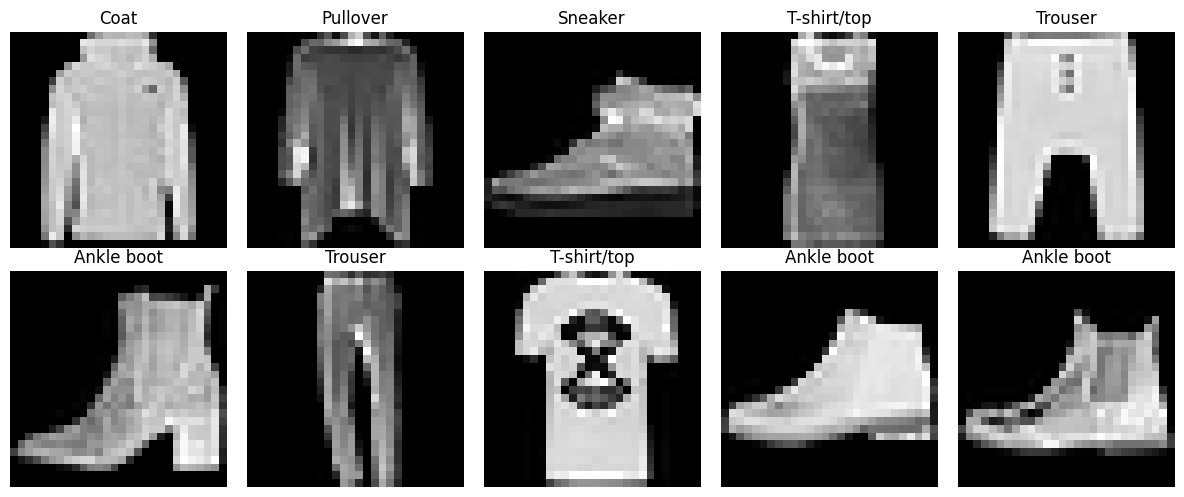

In [20]:

CLASS_NAMES = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_train[i].reshape(28, 28), cmap="gray")
    ax.set_title(CLASS_NAMES[y_train_split[i]])
    ax.axis("off")

plt.tight_layout()
plt.show()


In [21]:

def softmax_cross_entropy(logits, labels):
    labels = np.asarray(labels, dtype=np.int64)

    if logits.data.ndim != 2:
        raise ValueError("Logits must have shape (batch, classes).")

    n = logits.data.shape[0]
    if len(labels) != n:
        raise ValueError("Batch size and label count do not match.")

    shifted = logits.data - np.max(
        logits.data, axis=1, keepdims=True
    )

    exp_scores = np.exp(shifted)
    probs = exp_scores / exp_scores.sum(axis=1, keepdims=True)

    loss_value = -np.mean(
        np.log(np.maximum(probs[np.arange(n), labels], 1e-15))
    )

    loss = Tensor(
        loss_value,
        requires_grad=logits.requires_grad,
        _children=(logits,),
        _op="softmax_cross_entropy"
    )

    def backward():
        if not logits.requires_grad:
            return

        grad_logits = probs.copy()
        grad_logits[np.arange(n), labels] -= 1.0
        grad_logits /= n

        logits.grad += grad_logits * loss.grad

    loss._backward = backward
    return loss


In [22]:

class Linear:
    def __init__(self, in_features, out_features, rng):
        scale = np.sqrt(2.0 / in_features)

        self.W = Tensor(
            rng.standard_normal((in_features, out_features)) * scale,
            requires_grad=True
        )
        self.b = Tensor(
            np.zeros((1, out_features)),
            requires_grad=True
        )

    def __call__(self, x):
        return x @ self.W + self.b

    def parameters(self):
        return [self.W, self.b]


class MLP:
    def __init__(self, seed=42):
        rng = np.random.default_rng(seed)

        self.layers = [
            Linear(784, 256, rng),
            Linear(256, 128, rng),
            Linear(128, 10, rng),
        ]

    def __call__(self, x):
        x = self.layers[0](x).relu()
        x = self.layers[1](x).relu()
        x = self.layers[2](x)
        return x

    def parameters(self):
        params = []
        for layer in self.layers:
            params.extend(layer.parameters())
        return params


model = MLP()
print("Trainable parameter count:",
      sum(p.data.size for p in model.parameters()))


Trainable parameter count: 235146


In [23]:

sample_x = Tensor(X_train[:8])
sample_logits = model(sample_x)

print("Input shape:", sample_x.shape)
print("Output shape:", sample_logits.shape)
print("First prediction:", sample_logits.data[0])

assert sample_logits.shape == (8, 10)
print("Forward pass PASSED!")


Input shape: (8, 784)
Output shape: (8, 10)
First prediction: [ 0.19338796  0.13978705  1.30424486 -0.06562043 -0.78302799  0.78123638
  0.5819031  -0.3804508  -0.34855902  0.82039401]
Forward pass PASSED!


In [24]:

sample_labels = y_train_split[:8]

sample_logits = model(Tensor(X_train[:8]))
sample_loss = softmax_cross_entropy(sample_logits, sample_labels)
sample_loss.backward()

print("Initial batch loss:", float(sample_loss.data))
print("First weight gradient norm:",
      np.linalg.norm(model.layers[0].W.grad))

assert np.isfinite(sample_loss.data).all()
assert np.isfinite(model.layers[0].W.grad).all()
assert np.linalg.norm(model.layers[0].W.grad) > 0

print("Loss and backpropagation PASSED!")


Initial batch loss: 2.473089992309175
First weight gradient norm: 3.842622321474113
Loss and backpropagation PASSED!


In [25]:

class Adam:
    def __init__(
        self,
        parameters,
        lr=0.001,
        beta1=0.9,
        beta2=0.999,
        eps=1e-8
    ):
        self.parameters = list(parameters)
        self.lr = lr
        self.beta1 = beta1
        self.beta2 = beta2
        self.eps = eps
        self.t = 0

        self.m = [np.zeros_like(p.data) for p in self.parameters]
        self.v = [np.zeros_like(p.data) for p in self.parameters]

    def step(self):
        self.t += 1

        for i, p in enumerate(self.parameters):
            g = p.grad

            self.m[i] = (
                self.beta1 * self.m[i] + (1 - self.beta1) * g
            )
            self.v[i] = (
                self.beta2 * self.v[i] + (1 - self.beta2) * (g ** 2)
            )

            m_hat = self.m[i] / (1 - self.beta1 ** self.t)
            v_hat = self.v[i] / (1 - self.beta2 ** self.t)

            p.data -= self.lr * m_hat / (np.sqrt(v_hat) + self.eps)


In [26]:

def evaluate(model, X, y, batch_size=256):
    total_loss = 0.0
    correct = 0
    total = len(X)

    for start in range(0, total, batch_size):
        end = min(start + batch_size, total)

        xb = Tensor(X[start:end])
        yb = y[start:end]

        logits = model(xb)
        loss = softmax_cross_entropy(logits, yb)

        batch_n = end - start
        total_loss += float(loss.data) * batch_n
        correct += np.sum(logits.data.argmax(axis=1) == yb)

    return total_loss / total, correct / total


First loss: 2.255935722216414
Last loss: 0.4855983080406253


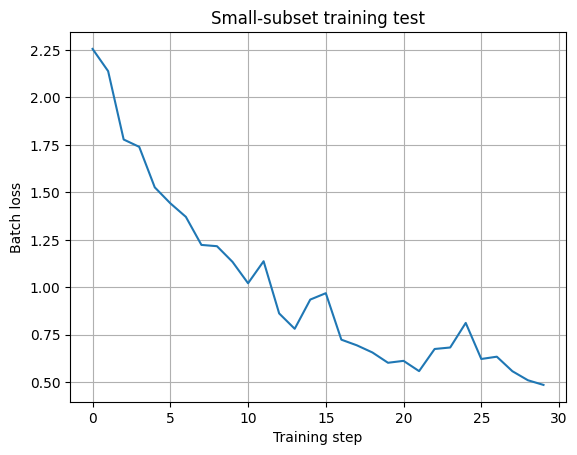

In [27]:

# A fresh model for the small test.
model = MLP(seed=42)
optimizer = Adam(model.parameters(), lr=0.001)

small_rng = np.random.default_rng(123)
small_indices = small_rng.choice(len(X_train), size=512, replace=False)

X_small = X_train[small_indices]
y_small = y_train_split[small_indices]

losses = []

for step in range(30):
    indices = small_rng.choice(len(X_small), size=64, replace=False)

    xb = Tensor(X_small[indices])
    yb = y_small[indices]

    logits = model(xb)
    loss = softmax_cross_entropy(logits, yb)
    loss.backward()
    optimizer.step()

    losses.append(float(loss.data))

print("First loss:", losses[0])
print("Last loss:", losses[-1])

plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("Batch loss")
plt.title("Small-subset training test")
plt.grid(True)
plt.show()


In [28]:

# Start fresh for the main experiment.
model = MLP(seed=42)
optimizer = Adam(model.parameters(), lr=0.001)

BATCH_SIZE = 256
EPOCHS = 20

history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_val_accuracy = 0.0
rng_train = np.random.default_rng(42)

for epoch in range(EPOCHS):
    start_time = time.time()
    order = rng_train.permutation(len(X_train))

    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    for start in range(0, len(order), BATCH_SIZE):
        batch_ids = order[start:start + BATCH_SIZE]

        xb = Tensor(X_train[batch_ids])
        yb = y_train_split[batch_ids]

        logits = model(xb)
        loss = softmax_cross_entropy(logits, yb)

        loss.backward()
        optimizer.step()

        n = len(batch_ids)
        total_loss += float(loss.data) * n
        total_correct += np.sum(logits.data.argmax(axis=1) == yb)
        total_seen += n

    train_loss = total_loss / total_seen
    train_accuracy = total_correct / total_seen

    val_loss, val_accuracy = evaluate(model, X_val, y_val)

    history["train_loss"].append(train_loss)
    history["train_accuracy"].append(train_accuracy)
    history["val_loss"].append(val_loss)
    history["val_accuracy"].append(val_accuracy)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1:02d}/{EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train acc={train_accuracy * 100:.2f}% | "
        f"val loss={val_loss:.4f} | "
        f"val acc={val_accuracy * 100:.2f}% | "
        f"time={elapsed:.1f}s"
    )

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        checkpoint = {
            "layers": [
                {
                    "W": layer.W.data.copy(),
                    "b": layer.b.data.copy()
                }
                for layer in model.layers
            ]
        }

        np.savez(
            "/content/best_mlp.npz",
            **{
                f"layer{i}_{key}": value
                for i, layer in enumerate(checkpoint["layers"])
                for key, value in layer.items()
            }
        )

print("Best validation accuracy:",
      f"{best_val_accuracy * 100:.2f}%")


Epoch 01/20 | train loss=0.5556 | train acc=80.84% | val loss=0.4072 | val acc=85.48% | time=8.1s
Epoch 02/20 | train loss=0.3913 | train acc=86.10% | val loss=0.3950 | val acc=85.58% | time=4.3s
Epoch 03/20 | train loss=0.3484 | train acc=87.58% | val loss=0.3705 | val acc=86.72% | time=4.9s
Epoch 04/20 | train loss=0.3219 | train acc=88.30% | val loss=0.3314 | val acc=88.06% | time=7.3s
Epoch 05/20 | train loss=0.3023 | train acc=88.95% | val loss=0.3157 | val acc=88.54% | time=3.8s
Epoch 06/20 | train loss=0.2810 | train acc=89.66% | val loss=0.3081 | val acc=88.70% | time=4.0s
Epoch 07/20 | train loss=0.2699 | train acc=90.13% | val loss=0.3117 | val acc=88.68% | time=7.6s
Epoch 08/20 | train loss=0.2558 | train acc=90.51% | val loss=0.2972 | val acc=89.18% | time=4.4s
Epoch 09/20 | train loss=0.2460 | train acc=90.81% | val loss=0.2859 | val acc=89.66% | time=6.1s
Epoch 10/20 | train loss=0.2358 | train acc=91.31% | val loss=0.2957 | val acc=89.44% | time=6.4s
Epoch 11/20 | train 

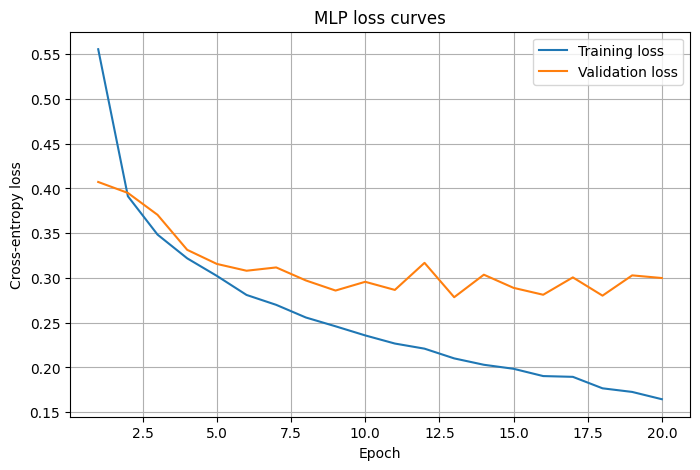

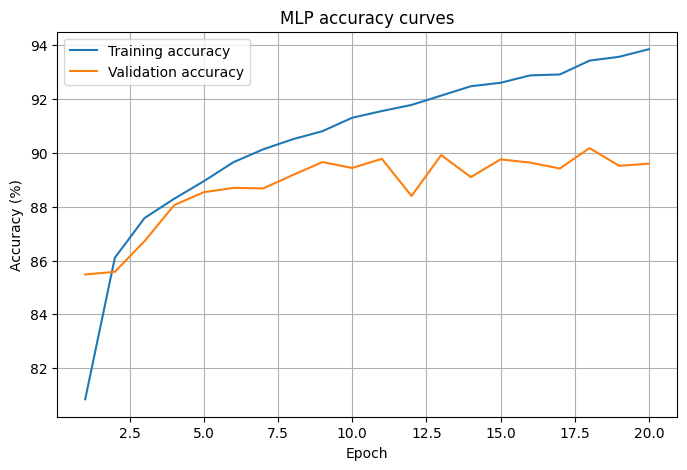

In [29]:

epochs = np.arange(1, len(history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history["train_loss"], label="Training loss")
plt.plot(epochs, history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("MLP loss curves")
plt.legend()
plt.grid(True)
plt.savefig("/content/mlp_loss.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epochs,
    np.array(history["train_accuracy"]) * 100,
    label="Training accuracy"
)
plt.plot(
    epochs,
    np.array(history["val_accuracy"]) * 100,
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("MLP accuracy curves")
plt.legend()
plt.grid(True)
plt.savefig("/content/mlp_accuracy.png", dpi=150)
plt.show()


In [30]:

checkpoint_data = np.load("/content/best_mlp.npz")

for i, layer in enumerate(model.layers):
    layer.W.data[:] = checkpoint_data[f"layer{i}_W"]
    layer.b.data[:] = checkpoint_data[f"layer{i}_b"]

test_loss, test_accuracy = evaluate(model, X_test, y_test)

print("=" * 45)
print("FINAL MLP TEST RESULTS")
print("=" * 45)
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")
print("Required accuracy: 88.00%")
print("Core accuracy target achieved:", test_accuracy >= 0.88)


FINAL MLP TEST RESULTS
Test loss: 0.3333
Test accuracy: 88.92%
Required accuracy: 88.00%
Core accuracy target achieved: True


In [31]:

np.savez(
    "/content/final_mlp.npz",
    **{
        f"layer{i}_{key}": value
        for i, layer in enumerate(model.layers)
        for key, value in [
            ("W", layer.W.data),
            ("b", layer.b.data),
        ]
    }
)

with open("/content/mlp_history.json", "w") as f:
    json.dump(history, f, indent=2)

print("Saved model: /content/final_mlp.npz")
print("Saved history: /content/mlp_history.json")
print("Saved plots: /content/mlp_loss.png and /content/mlp_accuracy.png")


Saved model: /content/final_mlp.npz
Saved history: /content/mlp_history.json
Saved plots: /content/mlp_loss.png and /content/mlp_accuracy.png


In [32]:

# Convert flattened images back to NCHW format.
X_train_cnn = X_train.reshape(-1, 1, 28, 28)
X_val_cnn = X_val.reshape(-1, 1, 28, 28)
X_test_cnn = X_test.reshape(-1, 1, 28, 28)

print("CNN training images:", X_train_cnn.shape)
print("CNN validation images:", X_val_cnn.shape)
print("CNN test images:", X_test_cnn.shape)

assert X_train_cnn.shape[1:] == (1, 28, 28)
assert X_val_cnn.shape[1:] == (1, 28, 28)
assert X_test_cnn.shape[1:] == (1, 28, 28)


CNN training images: (55000, 1, 28, 28)
CNN validation images: (5000, 1, 28, 28)
CNN test images: (10000, 1, 28, 28)


In [33]:


class Conv2D:
    def __init__(
        self,
        in_channels,
        out_channels,
        kernel_size=3,
        padding=1,
        seed=42
    ):
        self.in_channels = in_channels
        self.out_channels = out_channels
        self.kernel_size = kernel_size
        self.padding = padding

        rng = np.random.default_rng(seed)
        k = kernel_size
        fan_in = in_channels * k * k

        # He initialization
        self.W = Tensor(
            rng.standard_normal(
                (out_channels, in_channels, k, k)
            ) * np.sqrt(2.0 / fan_in),
            requires_grad=True
        )

        self.b = Tensor(
            np.zeros(out_channels),
            requires_grad=True
        )

    def __call__(self, x):
        if x.data.ndim != 4:
            raise ValueError(
                "Conv2D expects input shape (N, C, H, W)."
            )

        n, cin, h, w = x.shape
        k = self.kernel_size
        p = self.padding

        if cin != self.in_channels:
            raise ValueError("Input channel count mismatch.")

        # Padding
        xp = np.pad(
            x.data,
            ((0, 0), (0, 0), (p, p), (p, p)),
            mode="constant"
        )

        # Extract sliding windows.
        # Shape: (N, Cin, Hout, Wout, K, K)
        windows = np.lib.stride_tricks.sliding_window_view(
            xp, (k, k), axis=(2, 3)
        )

        out_h, out_w = windows.shape[2:4]

        # Arrange each image patch as a row.
        patches = windows.transpose(
            0, 2, 3, 1, 4, 5
        ).reshape(-1, cin * k * k)

        weight_matrix = self.W.data.reshape(
            self.out_channels, -1
        )

        # Forward convolution
        result = patches @ weight_matrix.T
        result += self.b.data

        result = result.reshape(
            n, out_h, out_w, self.out_channels
        ).transpose(0, 3, 1, 2)

        out = Tensor(
            result,
            requires_grad=(
                x.requires_grad
                or self.W.requires_grad
                or self.b.requires_grad
            ),
            _children=(x, self.W, self.b),
            _op="conv2d"
        )

        def backward():
            # Convert output gradients to row format.
            # Shape: (N * Hout * Wout, Cout)
            grad_out = out.grad.transpose(
                0, 2, 3, 1
            ).reshape(-1, self.out_channels)

            # Weight gradients
            if self.W.requires_grad:
                grad_w = grad_out.T @ patches
                self.W.grad += grad_w.reshape(
                    self.W.shape
                )

            # Bias gradients
            if self.b.requires_grad:
                self.b.grad += grad_out.sum(axis=0)

            # Input gradients
            if x.requires_grad:
                grad_patches = (
                    grad_out @ weight_matrix
                ).reshape(
                    n, out_h, out_w, cin, k, k
                )

                # Shape of grad_patches:
                # (N, Hout, Wout, Cin, K, K)
                grad_xp = np.zeros_like(xp)

                # Scatter each patch gradient back into
                # its corresponding input-image position.
                for i in range(k):
                    for j in range(k):
                        patch_grad = grad_patches[
                            :, :, :, :, i, j
                        ].transpose(0, 3, 1, 2)

                        grad_xp[
                            :, :, i:i + out_h,
                            j:j + out_w
                        ] += patch_grad

                # Remove padding from the input gradient.
                if p > 0:
                    grad_x = grad_xp[
                        :, :, p:-p, p:-p
                    ]
                else:
                    grad_x = grad_xp

                x.grad += grad_x

        out._backward = backward
        return out

    def parameters(self):
        return [self.W, self.b]


print("Corrected Conv2D class defined successfully!")



Corrected Conv2D class defined successfully!


In [34]:

conv_test = Conv2D(
    in_channels=1,
    out_channels=2,
    kernel_size=3,
    padding=1,
    seed=1
)

x_test_conv = Tensor(
    np.random.default_rng(10).normal(size=(2, 1, 5, 5)),
    requires_grad=True
)

y_test_conv = conv_test(x_test_conv)

print("Input shape:", x_test_conv.shape)
print("Output shape:", y_test_conv.shape)

test_loss_conv = (y_test_conv * y_test_conv).mean()
test_loss_conv.backward()

print("Input gradient shape:", x_test_conv.grad.shape)
print("Weight gradient shape:", conv_test.W.grad.shape)
print("Bias gradient shape:", conv_test.b.grad.shape)

assert y_test_conv.shape == (2, 2, 5, 5)
assert x_test_conv.grad.shape == (2, 1, 5, 5)
assert np.isfinite(conv_test.W.grad).all()
assert np.isfinite(x_test_conv.grad).all()

print("Conv2D forward/backward test PASSED!")


Input shape: (2, 1, 5, 5)
Output shape: (2, 2, 5, 5)
Input gradient shape: (2, 1, 5, 5)
Weight gradient shape: (2, 1, 3, 3)
Bias gradient shape: (2,)
Conv2D forward/backward test PASSED!


In [35]:

def numerical_check_parameter(loss_function, parameter, eps=1e-6):
    # Compute analytical gradient.
    loss = loss_function()
    loss.backward()
    analytical = parameter.grad.copy()

    numerical = np.zeros_like(parameter.data)

    for index in np.ndindex(parameter.shape):
        original = parameter.data[index]

        parameter.data[index] = original + eps
        plus = float(loss_function().data)

        parameter.data[index] = original - eps
        minus = float(loss_function().data)

        parameter.data[index] = original

        numerical[index] = (plus - minus) / (2 * eps)

    error = np.abs(analytical - numerical) / np.maximum(
        1e-12, np.abs(analytical) + np.abs(numerical)
    )

    max_error = float(error.max())
    print("Maximum relative error:", max_error)

    assert max_error < 1e-5, "Convolution gradient check FAILED!"
    print("Convolution gradient check PASSED!")
    return max_error


# Small example to keep the finite-difference test fast.
conv_check = Conv2D(1, 1, kernel_size=2, padding=0, seed=5)
x_check = Tensor(
    np.random.default_rng(6).normal(size=(1, 1, 3, 3)),
    requires_grad=True
)

def conv_check_loss():
    result = conv_check(x_check)
    return (result * result).mean()

numerical_check_parameter(conv_check_loss, conv_check.W)


Maximum relative error: 1.7021639165239753e-10
Convolution gradient check PASSED!


1.7021639165239753e-10

In [36]:

class MaxPool2D:
    def __init__(self, kernel_size=2, stride=2):
        self.kernel_size = kernel_size
        self.stride = stride

    def __call__(self, x):
        if x.data.ndim != 4:
            raise ValueError(
                "MaxPool2D expects input shape (N, C, H, W)."
            )

        n, c, h, w = x.shape
        k = self.kernel_size
        s = self.stride

        out_h = (h - k) // s + 1
        out_w = (w - k) // s + 1

        # Extract pooling windows.
        windows = np.lib.stride_tricks.sliding_window_view(
            x.data, (k, k), axis=(2, 3)
        )

        # Apply the configured stride.
        windows = windows[:, :, ::s, ::s, :, :]
        windows = windows[:, :, :out_h, :out_w, :, :]

        # Flatten each pooling window.
        flat = windows.reshape(
            n, c, out_h, out_w, k * k
        )

        # Save the location of each maximum.
        argmax = flat.argmax(axis=-1)
        result = flat.max(axis=-1)

        out = Tensor(
            result,
            requires_grad=x.requires_grad,
            _children=(x,),
            _op="maxpool2d"
        )

        def backward():
            if not x.requires_grad:
                return

            grad_x = np.zeros_like(x.data)

            # Send each output gradient only to the
            # position that was the maximum.
            for i in range(k):
                for j in range(k):
                    mask = (argmax == i * k + j)

                    # Shape: (N, C, Hout, Wout)
                    contribution = out.grad * mask

                    # Add gradients to the corresponding
                    # non-overlapping input positions.
                    grad_x[
                        :, :,
                        i:i + out_h * s:s,
                        j:j + out_w * s:s
                    ] += contribution

            x.grad += grad_x

        out._backward = backward
        return out


print("Corrected MaxPool2D class defined successfully!")



Corrected MaxPool2D class defined successfully!


In [37]:

pool = MaxPool2D(2, 2)

pool_input = Tensor(
    np.arange(16, dtype=np.float64).reshape(1, 1, 4, 4),
    requires_grad=True
)

pool_output = pool(pool_input)
print("Pooled output:\n", pool_output.data)

pool_output.sum().backward()

print("Input gradient:\n", pool_input.grad)

assert pool_output.shape == (1, 1, 2, 2)
assert np.allclose(pool_output.data, [[[[5, 7], [13, 15]]]])
assert np.isclose(pool_input.grad.sum(), 4.0)

print("MaxPool test PASSED!")


Pooled output:
 [[[[ 5.  7.]
   [13. 15.]]]]
Input gradient:
 [[[[0. 0. 0. 0.]
   [0. 1. 0. 1.]
   [0. 0. 0. 0.]
   [0. 1. 0. 1.]]]]
MaxPool test PASSED!


In [38]:

class BatchNorm2D:
    def __init__(self, channels, momentum=0.1, eps=1e-5):
        self.channels = channels
        self.momentum = momentum
        self.eps = eps

        self.gamma = Tensor(np.ones(channels), requires_grad=True)
        self.beta = Tensor(np.zeros(channels), requires_grad=True)

        self.running_mean = np.zeros(channels)
        self.running_var = np.ones(channels)
        self.training = True

    def train(self):
        self.training = True

    def eval(self):
        self.training = False

    def __call__(self, x):
        n, c, h, w = x.shape
        if c != self.channels:
            raise ValueError("BatchNorm channel mismatch.")

        if self.training:
            mean = x.data.mean(axis=(0, 2, 3))
            var = x.data.var(axis=(0, 2, 3))

            self.running_mean = (
                (1 - self.momentum) * self.running_mean
                + self.momentum * mean
            )
            self.running_var = (
                (1 - self.momentum) * self.running_var
                + self.momentum * var
            )
        else:
            mean = self.running_mean
            var = self.running_var

        inv_std = 1.0 / np.sqrt(var + self.eps)
        x_hat = (
            (x.data - mean[None, :, None, None])
            * inv_std[None, :, None, None]
        )

        gamma = self.gamma.data[None, :, None, None]
        beta = self.beta.data[None, :, None, None]

        result = x_hat * gamma + beta

        out = Tensor(
            result,
            requires_grad=(
                x.requires_grad
                or self.gamma.requires_grad
                or self.beta.requires_grad
            ),
            _children=(x, self.gamma, self.beta),
            _op="batchnorm2d"
        )

        def backward():
            dy = out.grad

            if self.gamma.requires_grad:
                self.gamma.grad += (
                    dy * x_hat
                ).sum(axis=(0, 2, 3))

            if self.beta.requires_grad:
                self.beta.grad += dy.sum(axis=(0, 2, 3))

            if x.requires_grad:
                m = n * h * w
                dxhat = dy * gamma
                sum_dxhat = dxhat.sum(axis=(0, 2, 3), keepdims=True)
                sum_dxhat_xhat = (
                    (dxhat * x_hat).sum(
                        axis=(0, 2, 3), keepdims=True
                    )
                )

                dx = (inv_std[None, :, None, None] / m) * (
                    m * dxhat
                    - sum_dxhat
                    - x_hat * sum_dxhat_xhat
                )

                x.grad += dx

        out._backward = backward
        return out

    def parameters(self):
        return [self.gamma, self.beta]


In [39]:

class Dropout:
    def __init__(self, p=0.25, seed=42):
        if not 0 <= p < 1:
            raise ValueError("Dropout probability must be in [0, 1).")

        self.p = p
        self.rng = np.random.default_rng(seed)
        self.training = True

    def train(self):
        self.training = True

    def eval(self):
        self.training = False

    def __call__(self, x):
        if not self.training or self.p == 0:
            mask = np.ones_like(x.data)
        else:
            mask = (
                self.rng.random(x.shape) >= self.p
            ).astype(np.float64) / (1 - self.p)

        out = Tensor(
            x.data * mask,
            requires_grad=x.requires_grad,
            _children=(x,),
            _op="dropout"
        )

        def backward():
            if x.requires_grad:
                x.grad += out.grad * mask

        out._backward = backward
        return out


In [40]:

class CNN:
    def __init__(self, seed=42):
        rng = np.random.default_rng(seed)

        self.conv1 = Conv2D(1, 16, kernel_size=3, padding=1, seed=seed)
        self.bn1 = BatchNorm2D(16)
        self.pool1 = MaxPool2D(2, 2)

        self.conv2 = Conv2D(16, 32, kernel_size=3, padding=1, seed=seed + 1)
        self.bn2 = BatchNorm2D(32)
        self.pool2 = MaxPool2D(2, 2)

        self.fc1 = Linear(32 * 7 * 7, 128, rng)
        self.dropout = Dropout(p=0.25, seed=seed + 2)
        self.fc2 = Linear(128, 10, rng)

    def __call__(self, x):
        x = self.conv1(x)
        x = self.bn1(x).relu()
        x = self.pool1(x)

        x = self.conv2(x)
        x = self.bn2(x).relu()
        x = self.pool2(x)

        x = x.reshape(x.shape[0], -1)
        x = self.fc1(x).relu()
        x = self.dropout(x)
        x = self.fc2(x)

        return x

    def parameters(self):
        params = []
        for layer in [
            self.conv1, self.bn1,
            self.conv2, self.bn2,
            self.fc1, self.fc2
        ]:
            params.extend(layer.parameters())
        return params

    def train(self):
        self.bn1.train()
        self.bn2.train()
        self.dropout.train()

    def eval(self):
        self.bn1.eval()
        self.bn2.eval()
        self.dropout.eval()


In [41]:

cnn = CNN(seed=42)

cnn.train()
sample = Tensor(X_train_cnn[:4])
sample_output = cnn(sample)

print("Input:", sample.shape)
print("Output:", sample_output.shape)
print("Number of trainable parameters:",
      sum(p.data.size for p in cnn.parameters()))

assert sample_output.shape == (4, 10)
assert all(np.isfinite(p.data).all() for p in cnn.parameters())

print("CNN forward pass PASSED!")


Input: (4, 1, 28, 28)
Output: (4, 10)
Number of trainable parameters: 207018
CNN forward pass PASSED!


In [42]:

cnn.train()

sample = Tensor(X_train_cnn[:4])
sample_labels = y_train_split[:4]

sample_logits = cnn(sample)
sample_loss = softmax_cross_entropy(sample_logits, sample_labels)
sample_loss.backward()

for name, layer in [
    ("conv1", cnn.conv1),
    ("conv2", cnn.conv2),
    ("fc1", cnn.fc1),
    ("fc2", cnn.fc2)
]:
    grad_norm = np.linalg.norm(layer.parameters()[0].grad)
    print(name, "gradient norm:", grad_norm)
    assert np.isfinite(grad_norm)
    assert grad_norm > 0

print("CNN backward pass PASSED!")


conv1 gradient norm: 2.481763072901511
conv2 gradient norm: 6.245252622685057
fc1 gradient norm: 23.391946596117688
fc2 gradient norm: 5.70463403815756
CNN backward pass PASSED!


In [43]:

def evaluate_cnn(model, X, y, batch_size=128):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = len(X)

    for start in range(0, total, batch_size):
        end = min(start + batch_size, total)

        xb = Tensor(X[start:end])
        yb = y[start:end]

        logits = model(xb)
        loss = softmax_cross_entropy(logits, yb)

        n = end - start
        total_loss += float(loss.data) * n
        correct += np.sum(logits.data.argmax(axis=1) == yb)

    return total_loss / total, correct / total


First loss: 4.143348691746995
Last loss: 1.5885162571498008


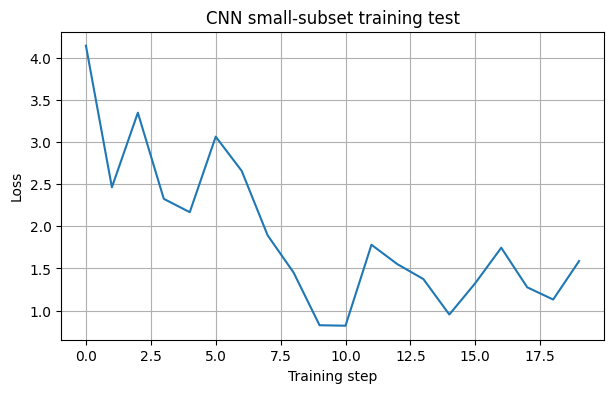

In [44]:

cnn = CNN(seed=42)
cnn_optimizer = Adam(cnn.parameters(), lr=0.001)

rng_small = np.random.default_rng(123)
small_ids = rng_small.choice(
    len(X_train_cnn), size=512, replace=False
)

losses_cnn = []

for step in range(20):
    cnn.train()

    batch_ids = rng_small.choice(
        small_ids, size=16, replace=False
    )

    xb = Tensor(X_train_cnn[batch_ids])
    yb = y_train_split[batch_ids]

    logits = cnn(xb)
    loss = softmax_cross_entropy(logits, yb)
    loss.backward()
    cnn_optimizer.step()

    losses_cnn.append(float(loss.data))

print("First loss:", losses_cnn[0])
print("Last loss:", losses_cnn[-1])

plt.figure(figsize=(7, 4))
plt.plot(losses_cnn)
plt.xlabel("Training step")
plt.ylabel("Loss")
plt.title("CNN small-subset training test")
plt.grid(True)
plt.show()


In [45]:

cnn = CNN(seed=42)
cnn_optimizer = Adam(cnn.parameters(), lr=0.001)

CNN_BATCH_SIZE = 16
CNN_EPOCHS = 5

cnn_history = {
    "train_loss": [],
    "train_accuracy": [],
    "val_loss": [],
    "val_accuracy": [],
}

best_cnn_val_accuracy = -1.0
rng_cnn = np.random.default_rng(42)

def save_cnn_checkpoint(model, path):
    values = {}

    for i, layer in enumerate(model.parameters()):
        values[f"param_{i}"] = layer.data.copy()

    values["bn1_running_mean"] = model.bn1.running_mean.copy()
    values["bn1_running_var"] = model.bn1.running_var.copy()
    values["bn2_running_mean"] = model.bn2.running_mean.copy()
    values["bn2_running_var"] = model.bn2.running_var.copy()

    np.savez(path, **values)


for epoch in range(CNN_EPOCHS):
    cnn.train()
    start_time = time.time()

    order = rng_cnn.permutation(len(X_train_cnn))
    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    for start in range(0, len(order), CNN_BATCH_SIZE):
        ids = order[start:start + CNN_BATCH_SIZE]

        xb = Tensor(X_train_cnn[ids])
        yb = y_train_split[ids]

        logits = cnn(xb)
        loss = softmax_cross_entropy(logits, yb)

        loss.backward()
        cnn_optimizer.step()

        n = len(ids)
        total_loss += float(loss.data) * n
        total_correct += np.sum(
            logits.data.argmax(axis=1) == yb
        )
        total_seen += n

    train_loss = total_loss / total_seen
    train_accuracy = total_correct / total_seen

    val_loss, val_accuracy = evaluate_cnn(
        cnn, X_val_cnn, y_val, batch_size=128
    )

    cnn_history["train_loss"].append(train_loss)
    cnn_history["train_accuracy"].append(train_accuracy)
    cnn_history["val_loss"].append(val_loss)
    cnn_history["val_accuracy"].append(val_accuracy)

    elapsed = time.time() - start_time

    print(
        f"Epoch {epoch + 1}/{CNN_EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train acc={train_accuracy * 100:.2f}% | "
        f"val loss={val_loss:.4f} | "
        f"val acc={val_accuracy * 100:.2f}% | "
        f"time={elapsed / 60:.1f} min"
    )

    if val_accuracy > best_cnn_val_accuracy:
        best_cnn_val_accuracy = val_accuracy
        save_cnn_checkpoint(cnn, "/content/best_cnn.npz")

with open("/content/cnn_history.json", "w") as f:
    json.dump(cnn_history, f, indent=2)

print("Best validation accuracy:",
      f"{best_cnn_val_accuracy * 100:.2f}%")


Epoch 1/5 | train loss=0.4550 | train acc=83.41% | val loss=0.3066 | val acc=88.56% | time=4.6 min
Epoch 2/5 | train loss=0.3129 | train acc=88.53% | val loss=0.2576 | val acc=90.78% | time=4.6 min
Epoch 3/5 | train loss=0.2688 | train acc=90.17% | val loss=0.2501 | val acc=90.74% | time=5.0 min
Epoch 4/5 | train loss=0.2430 | train acc=91.01% | val loss=0.2424 | val acc=91.00% | time=5.1 min
Epoch 5/5 | train loss=0.2163 | train acc=92.01% | val loss=0.2419 | val acc=91.68% | time=5.0 min
Best validation accuracy: 91.68%


In [1]:
import os

for path in [
    "/content/best_cnn.npz",
    "/content/final_cnn.npz",
    "/content/cnn_history.json",
]:
    print(path, "FOUND" if os.path.exists(path) else "NOT FOUND")

/content/best_cnn.npz FOUND
/content/final_cnn.npz NOT FOUND
/content/cnn_history.json NOT FOUND


In [3]:

from google.colab import drive
import os
import shutil

drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/DeepLearningProject"
os.makedirs(SAVE_DIR, exist_ok=True)

shutil.copy2(
    "/content/best_cnn.npz",
    os.path.join(SAVE_DIR, "best_cnn.npz")
)

print("Checkpoint backed up to Google Drive!")


Mounted at /content/drive
Checkpoint backed up to Google Drive!


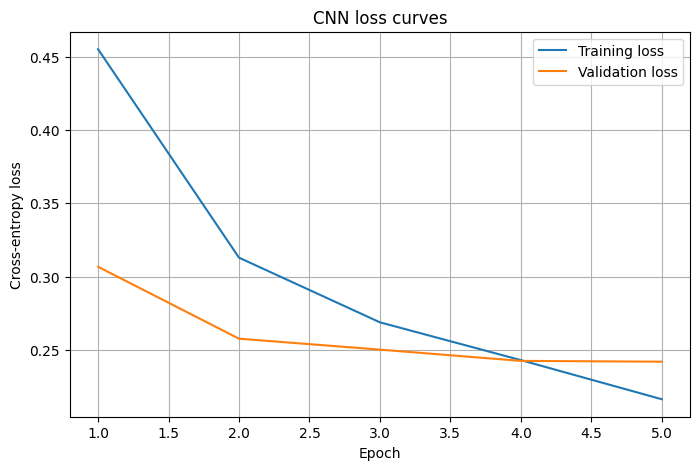

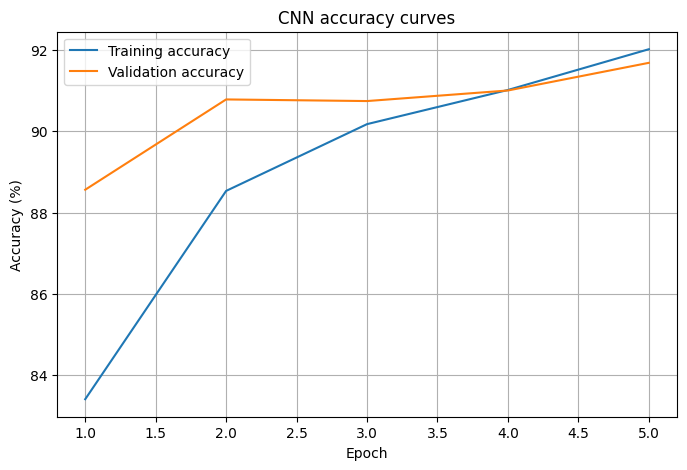

In [46]:

epochs = np.arange(1, len(cnn_history["train_loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, cnn_history["train_loss"], label="Training loss")
plt.plot(epochs, cnn_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("CNN loss curves")
plt.legend()
plt.grid(True)
plt.savefig("/content/cnn_loss.png", dpi=150)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(
    epochs, np.array(cnn_history["train_accuracy"]) * 100,
    label="Training accuracy"
)
plt.plot(
    epochs, np.array(cnn_history["val_accuracy"]) * 100,
    label="Validation accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN accuracy curves")
plt.legend()
plt.grid(True)
plt.savefig("/content/cnn_accuracy.png", dpi=150)
plt.show()


In [47]:

def load_cnn_checkpoint(model, path):
    saved = np.load(path)
    params = model.parameters()

    for i, p in enumerate(params):
        p.data[:] = saved[f"param_{i}"]

    model.bn1.running_mean = saved["bn1_running_mean"].copy()
    model.bn1.running_var = saved["bn1_running_var"].copy()
    model.bn2.running_mean = saved["bn2_running_mean"].copy()
    model.bn2.running_var = saved["bn2_running_var"].copy()


load_cnn_checkpoint(cnn, "/content/best_cnn.npz")

print("Best CNN checkpoint loaded.")


Best CNN checkpoint loaded.


In [48]:
test_loss_cnn, test_accuracy_cnn = evaluate_cnn(
    cnn, X_test_cnn, y_test, batch_size=16
)

print("=" * 45)
print("FINAL CNN TEST RESULTS")
print("=" * 45)
print(f"Test loss: {test_loss_cnn:.4f}")
print(f"Test accuracy: {test_accuracy_cnn * 100:.2f}%")
print("Required target: 91.00%")
print("Target achieved:", test_accuracy_cnn >= 0.91)

FINAL CNN TEST RESULTS
Test loss: 0.2707
Test accuracy: 90.85%
Required target: 91.00%
Target achieved: False


In [49]:
load_cnn_checkpoint(cnn, "/content/best_cnn.npz")

val_loss, val_accuracy = evaluate_cnn(
    cnn, X_val_cnn, y_val, batch_size=16
)

print(f"Best checkpoint validation accuracy: {val_accuracy * 100:.2f}%")

Best checkpoint validation accuracy: 91.68%


In [50]:
test_loss_cnn, test_accuracy_cnn = evaluate_cnn(
    cnn, X_test_cnn, y_test, batch_size=16
)

print(f"Test accuracy: {test_accuracy_cnn * 100:.2f}%")

Test accuracy: 90.85%


In [ ]:

import os
import json
import time
import numpy as np

# Save progress in Google Drive
SAVE_DIR = "/content/drive/MyDrive/DeepLearningProject"
os.makedirs(SAVE_DIR, exist_ok=True)
BEST_PATH = os.path.join(SAVE_DIR, "best_cnn.npz")

# Continue from the currently loaded best checkpoint
CNN_BATCH_SIZE = 16
CONTINUE_EPOCHS = 3

# Use a smaller learning rate for fine-tuning
cnn_optimizer = Adam(cnn.parameters(), lr=0.0003)

# Keep the best checkpoint's validation score as the baseline
best_cnn_val_accuracy = val_accuracy

for epoch in range(CONTINUE_EPOCHS):
    cnn.train()
    start_time = time.time()

    order = np.random.default_rng(100 + epoch).permutation(
        len(X_train_cnn)
    )
    total_loss = 0.0
    total_correct = 0
    total_seen = 0

    for start in range(0, len(order), CNN_BATCH_SIZE):
        ids = order[start:start + CNN_BATCH_SIZE]

        xb = Tensor(X_train_cnn[ids])
        yb = y_train_split[ids]

        logits = cnn(xb)
        loss = softmax_cross_entropy(logits, yb)
        loss.backward()
        cnn_optimizer.step()

        n = len(ids)
        total_loss += float(loss.data) * n
        total_correct += np.sum(logits.data.argmax(axis=1) == yb)
        total_seen += n

    train_loss = total_loss / total_seen
    train_accuracy = total_correct / total_seen

    val_loss, val_accuracy = evaluate_cnn(
        cnn, X_val_cnn, y_val, batch_size=16
    )

    print(
        f"Fine-tune epoch {epoch + 1}/{CONTINUE_EPOCHS} | "
        f"train loss={train_loss:.4f} | "
        f"train acc={train_accuracy * 100:.2f}% | "
        f"val loss={val_loss:.4f} | "
        f"val acc={val_accuracy * 100:.2f}% | "
        f"time={(time.time() - start_time) / 60:.1f} min"
    )

    # Save only when validation accuracy improves
    if val_accuracy > best_cnn_val_accuracy:
        best_cnn_val_accuracy = val_accuracy
        save_cnn_checkpoint(cnn, BEST_PATH)
        print("Improved checkpoint saved to Google Drive.")

# Restore the best validation checkpoint, not simply the last epoch
load_cnn_checkpoint(cnn, BEST_PATH)

print(
    f"\nBest validation accuracy: "
    f"{best_cnn_val_accuracy * 100:.2f}%"
)
